In [2]:
import os, json, time, pickle, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

BASE   = r'D:\FYP\Eco-Twin'
V2_DIR = os.path.join(BASE, 'v2_clean')
OUT    = os.path.join(V2_DIR, 'ecotwin_outputs')
DATA_DIR, SCALER_DIR = os.path.join(OUT,'data'), os.path.join(OUT,'scalers')
PLOT_DIR, MODEL_DIR, RESULTS_DIR = os.path.join(OUT,'plots'), os.path.join(OUT,'models'), os.path.join(OUT,'results')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

X_train  = np.load(os.path.join(DATA_DIR,'X_train.npy'))
Y_train  = np.load(os.path.join(DATA_DIR,'Y_train.npy'))
At_train = np.load(os.path.join(DATA_DIR,'At_train.npy'))
X_val    = np.load(os.path.join(DATA_DIR,'X_val.npy'))
Y_val    = np.load(os.path.join(DATA_DIR,'Y_val.npy'))
At_val   = np.load(os.path.join(DATA_DIR,'At_val.npy'))
X_test   = np.load(os.path.join(DATA_DIR,'X_test.npy'))
Y_test   = np.load(os.path.join(DATA_DIR,'Y_test.npy'))
At_test  = np.load(os.path.join(DATA_DIR,'At_test.npy'))

with open(os.path.join(SCALER_DIR,'pm25_scaler.pkl'),'rb') as f:
    pm25_scaler = pickle.load(f)

N, F = X_train.shape[2], X_train.shape[3]
print(f"Device {DEVICE} | N={N} stations | F={F} features")
print(f"Train {X_train.shape[0]:,} | Val {X_val.shape[0]:,} | Test {X_test.shape[0]:,} samples")

Device cuda | N=37 stations | F=14 features
Train 13,873 | Val 2,917 | Test 2,918 samples


In [3]:
class WindowDataset(Dataset):
    def __init__(self, X, Y, At):
        self.X, self.Y, self.At = X, Y, At
    def __len__(self):
        return self.X.shape[0]
    def __getitem__(self, i):
        return (torch.from_numpy(self.X[i]).float(),
                torch.from_numpy(self.At[i]).float(),
                torch.from_numpy(self.Y[i]).float())

BATCH_SIZE = 16
train_ds = WindowDataset(X_train, Y_train, At_train)
val_ds   = WindowDataset(X_val,   Y_val,   At_val)
test_ds  = WindowDataset(X_test,  Y_test,  At_test)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print(f"Batches — train {len(train_loader)} | val {len(val_loader)} | test {len(test_loader)}")

Batches — train 868 | val 183 | test 183


In [3]:
class WATGCN(nn.Module):
    """
    pool_mode : 'last'      -> use final timestep only (original)
                'attention' -> learned weighted pool over all 48 timesteps
    delta_mode: False       -> predict absolute PM2.5
                True        -> predict change from last observed value
    """
    def __init__(self, in_features, hidden_dim, gru_layers, attn_heads,
                 forecast_horizon, n_stations, dropout=0.2,
                 pool_mode='last', delta_mode=False):
        super().__init__()
        self.input_proj  = nn.Linear(in_features, hidden_dim)
        self.gcn_linear  = nn.Linear(hidden_dim, hidden_dim)
        self.gcn_norm    = nn.LayerNorm(hidden_dim)
        self.act         = nn.ReLU()
        self.gru         = nn.GRU(hidden_dim, hidden_dim, gru_layers,
                                  batch_first=True,
                                  dropout=dropout if gru_layers > 1 else 0)
        self.attention   = nn.MultiheadAttention(hidden_dim, attn_heads,
                                                 dropout=dropout, batch_first=True)
        self.attn_norm   = nn.LayerNorm(hidden_dim)
        self.dropout     = nn.Dropout(dropout)

        # learned pooling: scores each timestep, softmax -> weighted sum
        if pool_mode == 'attention':
            self.pool_score = nn.Linear(hidden_dim, 1)

        self.output_proj = nn.Linear(hidden_dim, forecast_horizon)
        self.H, self.FH  = hidden_dim, forecast_horizon
        self.pool_mode   = pool_mode
        self.delta_mode  = delta_mode
        self.last_pool_weights = None   # stored for visualisation

    def forward(self, X, At):
        B, T, N, Fdim = X.shape
        H = self.act(self.input_proj(X))

        I = torch.eye(N, device=At.device).unsqueeze(0).unsqueeze(0)
        A = At + I
        A = A / A.sum(dim=-1, keepdim=True).clamp(min=1e-6)

        H_agg = torch.matmul(A, H)
        H_agg = self.act(self.gcn_norm(self.gcn_linear(H_agg)))
        H_agg = H_agg + H

        H_flat = H_agg.permute(0,2,1,3).reshape(B*N, T, self.H)
        g, _ = self.gru(H_flat)
        g = self.dropout(g)
        a, _ = self.attention(g, g, g)
        a = self.attn_norm(a + g)                     # (B*N, T, H)

        if self.pool_mode == 'attention':
            scores = self.pool_score(a)               # (B*N, T, 1)
            w = torch.softmax(scores, dim=1)
            self.last_pool_weights = w.detach()
            pooled = (a * w).sum(dim=1)               # (B*N, H)
        else:
            pooled = a[:, -1, :]                      # (B*N, H)

        out = self.output_proj(pooled)                # (B*N, FH)
        out = out.reshape(B, N, self.FH).permute(0,2,1)   # (B, FH, N)

        if self.delta_mode:
            # last observed PM2.5 (feature index 0) at final input hour
            last_val = X[:, -1, :, 0]                 # (B, N)
            out = out + last_val.unsqueeze(1)         # broadcast over horizon

        return out

print("Model class defined — supports pool_mode and delta_mode variants.")

Model class defined — supports pool_mode and delta_mode variants.


In [4]:
def run_experiment(name, hidden_dim, gru_layers, pool_mode, delta_mode,
                   epochs=12, seed=42, attn_heads=4, dropout=0.2, lr=1e-3):
    torch.manual_seed(seed); np.random.seed(seed)

    model = WATGCN(in_features=F, hidden_dim=hidden_dim, gru_layers=gru_layers,
                   attn_heads=attn_heads, forecast_horizon=24, n_stations=N,
                   dropout=dropout, pool_mode=pool_mode,
                   delta_mode=delta_mode).to(DEVICE)

    opt  = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    crit = nn.MSELoss()
    n_params = sum(p.numel() for p in model.parameters())

    best_val, best_state, hist = float('inf'), None, {'train':[], 'val':[]}
    print(f"\n[{name}]  hidden={hidden_dim} gru={gru_layers} pool={pool_mode} "
          f"delta={delta_mode}  params={n_params:,}")
    print(f"  {'Ep':>3} | {'Train':>9} | {'Val':>9} | {'Time':>6}")

    for ep in range(1, epochs+1):
        t0 = time.time()
        model.train(); tr = 0.0
        for Xb, Ab, Yb in train_loader:
            Xb, Ab, Yb = Xb.to(DEVICE), Ab.to(DEVICE), Yb.to(DEVICE)
            opt.zero_grad()
            loss = crit(model(Xb, Ab), Yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            tr += loss.item() * Xb.size(0)
        tr /= len(train_ds)

        model.eval(); vl = 0.0
        with torch.no_grad():
            for Xb, Ab, Yb in val_loader:
                Xb, Ab, Yb = Xb.to(DEVICE), Ab.to(DEVICE), Yb.to(DEVICE)
                vl += crit(model(Xb, Ab), Yb).item() * Xb.size(0)
        vl /= len(val_ds)

        hist['train'].append(tr); hist['val'].append(vl)
        if vl < best_val:
            best_val = vl
            best_state = copy.deepcopy(model.state_dict())
        print(f"  {ep:>3} | {tr:>9.5f} | {vl:>9.5f} | {time.time()-t0:>5.1f}s")

    # test metrics using best checkpoint
    model.load_state_dict(best_state)
    model.eval()
    P, Ac = [], []
    with torch.no_grad():
        for Xb, Ab, Yb in test_loader:
            P.append(model(Xb.to(DEVICE), Ab.to(DEVICE)).cpu().numpy())
            Ac.append(Yb.numpy())
    ps, acs = np.concatenate(P), np.concatenate(Ac)
    inv = lambda x: pm25_scaler.inverse_transform(x.reshape(-1,1)).reshape(x.shape)
    pr, ar = inv(ps), inv(acs)
    rmse = np.sqrt(mean_squared_error(ar.flatten(), pr.flatten()))
    mae  = mean_absolute_error(ar.flatten(), pr.flatten())
    r2   = r2_score(ar.flatten(), pr.flatten())
    rmse_1h  = np.sqrt(mean_squared_error(ar[:,0,:].flatten(),  pr[:,0,:].flatten()))
    rmse_24h = np.sqrt(mean_squared_error(ar[:,23,:].flatten(), pr[:,23,:].flatten()))

    print(f"  -> best val {best_val:.5f} | RMSE {rmse:.2f} | MAE {mae:.2f} | R2 {r2:.4f}")

    return {'name':name, 'hidden':hidden_dim, 'gru':gru_layers,
            'pool':pool_mode, 'delta':delta_mode, 'params':n_params,
            'best_val':round(best_val,5), 'rmse':round(rmse,2),
            'mae':round(mae,2), 'r2':round(r2,4),
            'rmse_1h':round(rmse_1h,2), 'rmse_24h':round(rmse_24h,2),
            'history':hist, 'state':best_state}

print("Helper defined.")

Helper defined.


In [5]:
results = []
results.append(run_experiment('A_baseline', 64, 2, 'last',  False))
results.append(run_experiment('B_smaller',  32, 1, 'last',  False))

print("\n" + "="*60)
for r in results:
    print(f"  {r['name']:<14} val={r['best_val']:.5f}  RMSE={r['rmse']:.2f}  R2={r['r2']:.4f}  params={r['params']:,}")


[A_baseline]  hidden=64 gru=2 pool=last delta=False  params=73,496
   Ep |     Train |       Val |   Time
    1 |   0.40553 |   0.40780 |  26.6s
    2 |   0.32664 |   0.43141 |  22.4s
    3 |   0.29340 |   0.40428 |  22.7s
    4 |   0.26468 |   0.42172 |  22.6s
    5 |   0.24413 |   0.43224 |  22.6s
    6 |   0.22408 |   0.44536 |  22.5s
    7 |   0.20429 |   0.47033 |  22.1s
    8 |   0.19246 |   0.47068 |  21.9s
    9 |   0.18038 |   0.47987 |  21.7s
   10 |   0.17278 |   0.50215 |  21.8s
   11 |   0.16520 |   0.50495 |  21.6s
   12 |   0.15784 |   0.51132 |  21.6s
  -> best val 0.40428 | RMSE 64.51 | MAE 43.15 | R2 0.5898

[B_smaller]  hidden=32 gru=1 pool=last delta=False  params=13,016
   Ep |     Train |       Val |   Time
    1 |   0.43953 |   0.43061 |  15.9s
    2 |   0.35132 |   0.40885 |  14.3s
    3 |   0.32962 |   0.41976 |  14.3s
    4 |   0.31092 |   0.44075 |  14.3s
    5 |   0.29708 |   0.41702 |  14.6s
    6 |   0.28627 |   0.41164 |  15.3s
    7 |   0.27472 |   0.44

In [6]:
winner = min(results, key=lambda r: r['best_val'])
wh, wg = winner['hidden'], winner['gru']
print(f"Winner so far: {winner['name']} (hidden={wh}, gru={wg})\n")

results.append(run_experiment('C_attnpool', wh, wg, 'attention', False))

c_res = results[-1]
best_pool = 'attention' if c_res['best_val'] < winner['best_val'] else 'last'
print(f"\nBest pooling: {best_pool}\n")

results.append(run_experiment('D_delta', wh, wg, best_pool, True))

print("\n" + "="*60)
for r in results:
    print(f"  {r['name']:<14} val={r['best_val']:.5f}  RMSE={r['rmse']:.2f}  R2={r['r2']:.4f}")

Winner so far: B_smaller (hidden=32, gru=1)


[C_attnpool]  hidden=32 gru=1 pool=attention delta=False  params=13,049
   Ep |     Train |       Val |   Time
    1 |   0.48301 |   0.54253 |  14.9s
    2 |   0.40876 |   0.50468 |  14.4s
    3 |   0.36279 |   0.48489 |  14.3s
    4 |   0.33480 |   0.47292 |  14.3s
    5 |   0.31677 |   0.41167 |  14.3s
    6 |   0.30158 |   0.46212 |  14.3s
    7 |   0.29243 |   0.46947 |  14.3s
    8 |   0.28076 |   0.45349 |  14.3s
    9 |   0.27313 |   0.43701 |  14.3s
   10 |   0.26585 |   0.44336 |  14.3s
   11 |   0.25853 |   0.46788 |  14.3s
   12 |   0.25436 |   0.44930 |  14.3s
  -> best val 0.41167 | RMSE 66.99 | MAE 46.09 | R2 0.5575

Best pooling: last


[D_delta]  hidden=32 gru=1 pool=last delta=True  params=13,016
   Ep |     Train |       Val |   Time
    1 |   0.44538 |   0.42424 |  14.0s
    2 |   0.35599 |   0.40464 |  14.0s
    3 |   0.33095 |   0.40635 |  14.0s
    4 |   0.31320 |   0.39178 |  13.9s
    5 |   0.29984 |   0.40144 |  14.

      name  hidden  gru      pool  delta  params  best_val  rmse   mae     r2  rmse_1h  rmse_24h
   D_delta      32    1      last   True   13016   0.39133 66.71 43.58 0.5613    30.84     70.92
 B_smaller      32    1      last  False   13016   0.40379 64.83 43.54 0.5856    40.40     70.14
A_baseline      64    2      last  False   73496   0.40428 64.51 43.15 0.5898    38.35     69.10
C_attnpool      32    1 attention  False   13049   0.41167 66.99 46.09 0.5575    43.16     69.53


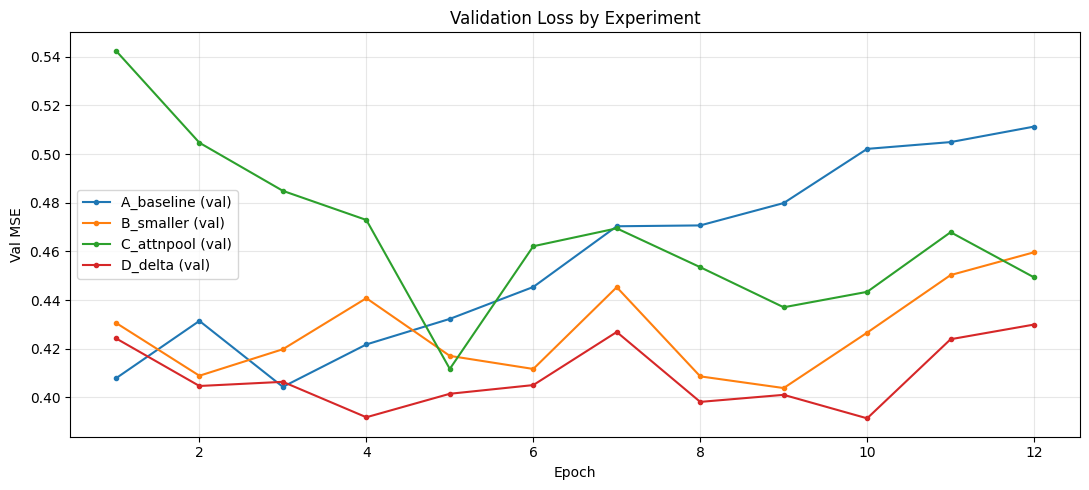


Best: D_delta
  RMSE 66.71 | MAE 43.58 | R2 0.5613
  RMSE +1h 30.84 | +24h 70.92


In [7]:
tbl = pd.DataFrame([{k:v for k,v in r.items() if k not in ('history','state')}
                    for r in results])
tbl = tbl.sort_values('best_val')
print(tbl.to_string(index=False))
tbl.to_csv(os.path.join(RESULTS_DIR,'experiment_comparison.csv'), index=False)

# loss curves
fig, ax = plt.subplots(figsize=(11,5))
for r in results:
    eps = range(1, len(r['history']['val'])+1)
    ax.plot(eps, r['history']['val'], marker='o', ms=3, label=f"{r['name']} (val)")
ax.set_xlabel('Epoch'); ax.set_ylabel('Val MSE'); ax.set_title('Validation Loss by Experiment')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR,'experiment_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()

# save best model + its config
best = min(results, key=lambda r: r['best_val'])
torch.save(best['state'], os.path.join(MODEL_DIR,'watgcn_best_experiment.pt'))
cfg = {'in_features':F, 'hidden_dim':best['hidden'], 'gru_layers':best['gru'],
       'attn_heads':4, 'forecast_horizon':24, 'n_stations':N, 'dropout':0.2,
       'pool_mode':best['pool'], 'delta_mode':bool(best['delta'])}
with open(os.path.join(MODEL_DIR,'best_config.json'),'w') as f:
    json.dump(cfg, f, indent=2)

print(f"\nBest: {best['name']}")
print(f"  RMSE {best['rmse']} | MAE {best['mae']} | R2 {best['r2']}")
print(f"  RMSE +1h {best['rmse_1h']} | +24h {best['rmse_24h']}")

In [6]:
import pandas as pd

# reload dataset just for timestamps
_df = pd.read_csv(os.path.join(V2_DIR,'EcoTwin_Final_Dataset.csv'),
                  parse_dates=['Timestamp'], usecols=['Timestamp'])
timestamps = np.array(sorted(_df['Timestamp'].unique()))
T = len(timestamps)

train_end_idx, val_end_idx = int(T*0.70), int(T*0.85)
TRAIN_END = pd.Timestamp(timestamps[train_end_idx-1])
VAL_END   = pd.Timestamp(timestamps[val_end_idx-1])

masks = {
    'train': timestamps <= TRAIN_END,
    'val'  : (timestamps > TRAIN_END) & (timestamps <= VAL_END),
    'test' : timestamps > VAL_END,
}

INPUT_WINDOW, HORIZON = 48, 24

def future_time_windows(ts_subset):
    ts = pd.DatetimeIndex(ts_subset)
    tf = np.stack([ts.hour, ts.dayofweek, ts.month,
                   (ts.dayofweek >= 5).astype(int)], axis=1).astype(np.float32)  # (T,4)
    n = len(ts) - (INPUT_WINDOW + HORIZON) + 1
    out = np.zeros((n, HORIZON, 4), dtype=np.float32)
    for i in range(n):
        out[i] = tf[i+INPUT_WINDOW : i+INPUT_WINDOW+HORIZON]
    return out

TF = {k: future_time_windows(timestamps[m]) for k, m in masks.items()}

# standardise using the same stats the feature scaler learned for cols 10-13
with open(os.path.join(SCALER_DIR,'feature_scaler.pkl'),'rb') as f:
    feat_scaler = pickle.load(f)
tm, ts_ = feat_scaler.mean_[10:14], feat_scaler.scale_[10:14]
for k in TF:
    TF[k] = ((TF[k] - tm) / ts_).astype(np.float32)

print(f"Future time features — train {TF['train'].shape} | val {TF['val'].shape} | test {TF['test'].shape}")
assert TF['train'].shape[0] == X_train.shape[0], "sample count mismatch"
print("Aligned with existing windows.")

Future time features — train (13873, 24, 4) | val (2917, 24, 4) | test (2918, 24, 4)
Aligned with existing windows.


In [7]:
class WindowDatasetTF(Dataset):
    def __init__(self, X, Y, At, TFut):
        self.X, self.Y, self.At, self.TF = X, Y, At, TFut
    def __len__(self):
        return self.X.shape[0]
    def __getitem__(self, i):
        return (torch.from_numpy(self.X[i]).float(),
                torch.from_numpy(self.At[i]).float(),
                torch.from_numpy(self.TF[i]).float(),
                torch.from_numpy(self.Y[i]).float())

train_ds_tf = WindowDatasetTF(X_train, Y_train, At_train, TF['train'])
val_ds_tf   = WindowDatasetTF(X_val,   Y_val,   At_val,   TF['val'])
test_ds_tf  = WindowDatasetTF(X_test,  Y_test,  At_test,  TF['test'])

train_loader_tf = DataLoader(train_ds_tf, batch_size=16, shuffle=True,  num_workers=0)
val_loader_tf   = DataLoader(val_ds_tf,   batch_size=16, shuffle=False, num_workers=0)
test_loader_tf  = DataLoader(test_ds_tf,  batch_size=16, shuffle=False, num_workers=0)
print(f"Loaders ready — {len(train_loader_tf)} train batches")

Loaders ready — 868 train batches


In [8]:
class WATGCN_TF(nn.Module):
    def __init__(self, in_features, hidden_dim, gru_layers, attn_heads,
                 forecast_horizon, n_stations, dropout=0.2, delta_mode=True,
                 n_time_feats=4):
        super().__init__()
        self.input_proj = nn.Linear(in_features, hidden_dim)
        self.gcn_linear = nn.Linear(hidden_dim, hidden_dim)
        self.gcn_norm   = nn.LayerNorm(hidden_dim)
        self.act        = nn.ReLU()
        self.gru        = nn.GRU(hidden_dim, hidden_dim, gru_layers, batch_first=True,
                                 dropout=dropout if gru_layers > 1 else 0)
        self.attention  = nn.MultiheadAttention(hidden_dim, attn_heads,
                                                dropout=dropout, batch_first=True)
        self.attn_norm  = nn.LayerNorm(hidden_dim)
        self.dropout    = nn.Dropout(dropout)

        # encodes the calendar info of each forecast hour
        self.time_enc = nn.Sequential(
            nn.Linear(n_time_feats, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim))
        # per-horizon decoder: history context + that hour's time -> 1 value
        self.decoder = nn.Sequential(
            nn.Linear(hidden_dim*2, hidden_dim), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(hidden_dim, 1))

        self.H, self.FH = hidden_dim, forecast_horizon
        self.delta_mode = delta_mode

    def forward(self, X, At, TFut):
        B, T, N, Fdim = X.shape
        H = self.act(self.input_proj(X))

        I = torch.eye(N, device=At.device).unsqueeze(0).unsqueeze(0)
        A = At + I
        A = A / A.sum(dim=-1, keepdim=True).clamp(min=1e-6)

        Hg = self.act(self.gcn_norm(self.gcn_linear(torch.matmul(A, H)))) + H
        Hf = Hg.permute(0,2,1,3).reshape(B*N, T, self.H)
        g, _ = self.gru(Hf)
        g = self.dropout(g)
        a, _ = self.attention(g, g, g)
        a = self.attn_norm(a + g)
        ctx = a[:, -1, :]                                  # (B*N, H)

        # future time -> embeddings, shared across stations
        t_emb = self.time_enc(TFut)                        # (B, FH, H)
        t_emb = t_emb.unsqueeze(1).expand(B, N, self.FH, self.H)
        t_emb = t_emb.reshape(B*N, self.FH, self.H)

        ctx_rep = ctx.unsqueeze(1).expand(-1, self.FH, -1)  # (B*N, FH, H)
        out = self.decoder(torch.cat([ctx_rep, t_emb], dim=-1)).squeeze(-1)  # (B*N, FH)
        out = out.reshape(B, N, self.FH).permute(0,2,1)

        if self.delta_mode:
            out = out + X[:, -1, :, 0].unsqueeze(1)
        return out

print("WATGCN_TF defined.")

WATGCN_TF defined.


In [ ]:
def run_tf_experiment(name, hidden_dim=32, gru_layers=1, delta_mode=True,
                      epochs=15, seed=42, lr=1e-3):
    torch.manual_seed(seed); np.random.seed(seed)
    model = WATGCN_TF(in_features=F, hidden_dim=hidden_dim, gru_layers=gru_layers,
                      attn_heads=4, forecast_horizon=24, n_stations=N,
                      dropout=0.2, delta_mode=delta_mode).to(DEVICE)
    opt  = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    crit = nn.MSELoss()
    print(f"\n[{name}] params={sum(p.numel() for p in model.parameters()):,}")
    print(f"  {'Ep':>3} | {'Train':>9} | {'Val':>9} | {'Time':>6}")

    best_val, best_state, hist = float('inf'), None, {'train':[], 'val':[]}
    for ep in range(1, epochs+1):
        t0 = time.time(); model.train(); tr = 0.0
        for Xb, Ab, Tb, Yb in train_loader_tf:
            Xb, Ab, Tb, Yb = Xb.to(DEVICE), Ab.to(DEVICE), Tb.to(DEVICE), Yb.to(DEVICE)
            opt.zero_grad()
            loss = crit(model(Xb, Ab, Tb), Yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            tr += loss.item()*Xb.size(0)
        tr /= len(train_ds_tf)

        model.eval(); vl = 0.0
        with torch.no_grad():
            for Xb, Ab, Tb, Yb in val_loader_tf:
                Xb, Ab, Tb, Yb = Xb.to(DEVICE), Ab.to(DEVICE), Tb.to(DEVICE), Yb.to(DEVICE)
                vl += crit(model(Xb, Ab, Tb), Yb).item()*Xb.size(0)
        vl /= len(val_ds_tf)

        hist['train'].append(tr); hist['val'].append(vl)
        if vl < best_val:
            best_val, best_state = vl, copy.deepcopy(model.state_dict())
        print(f"  {ep:>3} | {tr:>9.5f} | {vl:>9.5f} | {time.time()-t0:>5.1f}s")

    model.load_state_dict(best_state); model.eval()
    P, Ac = [], []
    with torch.no_grad():
        for Xb, Ab, Tb, Yb in test_loader_tf:
            P.append(model(Xb.to(DEVICE), Ab.to(DEVICE), Tb.to(DEVICE)).cpu().numpy())
            Ac.append(Yb.numpy())
    ps, acs = np.concatenate(P), np.concatenate(Ac)
    inv = lambda x: pm25_scaler.inverse_transform(x.reshape(-1,1)).reshape(x.shape)
    pr, ar = inv(ps), inv(acs)
    rmse = np.sqrt(mean_squared_error(ar.flatten(), pr.flatten()))
    mae  = mean_absolute_error(ar.flatten(), pr.flatten())
    r2   = r2_score(ar.flatten(), pr.flatten())
    print(f"  -> val {best_val:.5f} | RMSE {rmse:.2f} | MAE {mae:.2f} | R2 {r2:.4f}")
    print("  RMSE by horizon:")
    for h in [0,5,11,17,23]:
        print(f"    +{h+1:>2}h : {np.sqrt(mean_squared_error(ar[:,h,:].flatten(), pr[:,h,:].flatten())):.2f}")
    return {'name':name,'best_val':round(best_val,5),'rmse':round(rmse,2),
            'mae':round(mae,2),'r2':round(r2,4),'history':hist,'state':best_state,
            'preds':pr,'actual':ar}

res_E = run_tf_experiment('E_futuretime')

print("\n" + "="*58)
print(f"{'Experiment':<16} {'Val':>9} {'RMSE':>8} {'R2':>8}")
for r in results:
    print(f"{r['name']:<16} {r['best_val']:>9.5f} {r['rmse']:>8.2f} {r['r2']:>8.4f}")
print(f"{res_E['name']:<16} {res_E['best_val']:>9.5f} {res_E['rmse']:>8.2f} {res_E['r2']:>8.4f}")


[E_futuretime] params=15,553
   Ep |     Train |       Val |   Time
    1 |   0.43326 |   0.42755 |  20.4s
    2 |   0.36350 |   0.39816 |  15.3s
    3 |   0.34162 |   0.38788 |  15.2s
    4 |   0.33142 |   0.38543 |  15.4s
    5 |   0.32207 |   0.43010 |  15.7s
    6 |   0.31376 |   0.40166 |  15.4s
    7 |   0.30414 |   0.40712 |  15.4s


In [12]:
preds  = res_E['preds']    # (n_test, 24, N)
actual = res_E['actual']

# volatility = how much actual PM2.5 swung within each 24h window, per station
swing = actual.max(axis=1) - actual.min(axis=1)      # (n_test, N)

q33, q66 = np.percentile(swing, [33, 66])
print(f"Swing percentiles — 33rd: {q33:.1f}  66th: {q66:.1f} µg/m³\n")

groups = {
    'Stable   (low swing)' : swing <= q33,
    'Moderate            ' : (swing > q33) & (swing <= q66),
    'Volatile (high swing)': swing > q66,
}

print(f"{'Regime':<24} {'Samples':>9} {'RMSE':>8} {'MAE':>8} {'Mean swing':>12}")
print("-"*66)
for label, mask in groups.items():
    # mask is (n_test, N); expand to select across horizon
    a = actual.transpose(0,2,1)[mask]      # (n_selected, 24)
    p = preds.transpose(0,2,1)[mask]
    rmse = np.sqrt(((a - p)**2).mean())
    mae  = np.abs(a - p).mean()
    print(f"{label:<24} {mask.sum():>9,} {rmse:>8.2f} {mae:>8.2f} {swing[mask].mean():>12.1f}")

overall_rmse = np.sqrt(((actual - preds)**2).mean())
print(f"\nOverall RMSE: {overall_rmse:.2f}")

Swing percentiles — 33rd: 108.0  66th: 177.2 µg/m³

Regime                     Samples     RMSE      MAE   Mean swing
------------------------------------------------------------------
Stable   (low swing)        35,673    34.00    25.67         76.6
Moderate                    35,602    45.79    34.82        139.6
Volatile (high swing)       36,691    94.81    68.56        281.6

Overall RMSE: 64.25


In [13]:
sq_err = ((actual - preds)**2).transpose(0,2,1)   # (n_test, N, 24)
total_sq = sq_err.sum()

print(f"{'Regime':<24} {'% of samples':>13} {'% of total error':>18}")
print("-"*58)
for label, mask in groups.items():
    share_samples = mask.sum() / mask.size * 100
    share_error   = sq_err[mask].sum() / total_sq * 100
    print(f"{label:<24} {share_samples:>12.1f}% {share_error:>17.1f}%")

Regime                    % of samples   % of total error
----------------------------------------------------------
Stable   (low swing)             33.0%               9.3%
Moderate                         33.0%              16.8%
Volatile (high swing)            34.0%              74.0%


In [14]:
# per-window RMSE across all stations
win_rmse = np.sqrt(((actual - preds)**2).mean(axis=(1,2)))   # (n_test,)
best_i, worst_i = int(np.argmin(win_rmse)), int(np.argmax(win_rmse))
sti = 0

for label, i in [('BEST', best_i), ('WORST', worst_i)]:
    print(f"\n=== {label} forecast window (sample #{i}, RMSE {win_rmse[i]:.1f}) ===")
    print(f"{'Hour':>5} {'Actual':>9} {'Predicted':>11} {'Error':>9}")
    for h in range(0, 24, 3):
        a, p = actual[i,h,sti], preds[i,h,sti]
        print(f"  +{h+1:>2} {a:>9.1f} {p:>11.1f} {p-a:>+9.1f}")


=== BEST forecast window (sample #2080, RMSE 16.8) ===
 Hour    Actual   Predicted     Error
  + 1      57.5        71.1     +13.6
  + 4      68.5        73.8      +5.3
  + 7      74.2        68.1      -6.1
  +10      52.2        58.5      +6.2
  +13      49.8        46.8      -3.0
  +16      59.8        59.8      +0.1
  +19      61.8        72.3     +10.5
  +22      53.0        68.7     +15.7

=== WORST forecast window (sample #958, RMSE 184.5) ===
 Hour    Actual   Predicted     Error
  + 1     190.5       204.4     +13.9
  + 4     247.2       227.3     -19.9
  + 7     301.2       234.3     -67.0
  +10     370.5       256.1    -114.4
  +13     536.2       287.6    -248.7
  +16     441.5       243.5    -198.0
  +19     422.0       214.0    -208.0
  +22     370.0       187.6    -182.4


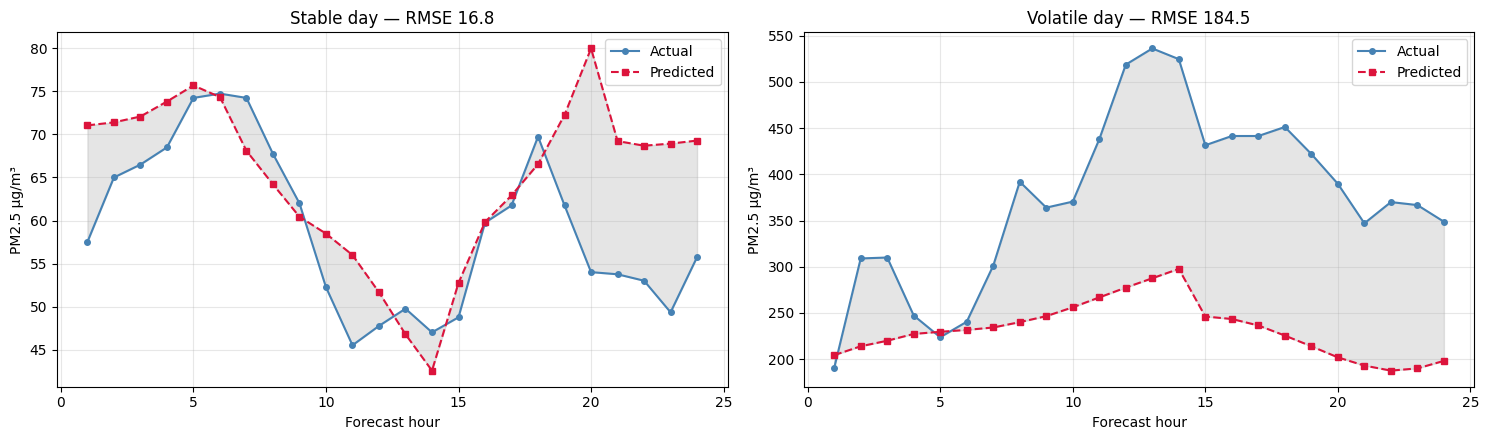

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, (label, i) in zip(axes, [('Stable day', best_i), ('Volatile day', worst_i)]):
    ax.plot(range(1,25), actual[i,:,sti], marker='o', ms=4, color='steelblue', label='Actual')
    ax.plot(range(1,25), preds[i,:,sti],  marker='s', ms=4, color='crimson', ls='--', label='Predicted')
    ax.fill_between(range(1,25), actual[i,:,sti], preds[i,:,sti], color='gray', alpha=0.2)
    ax.set_title(f'{label} — RMSE {win_rmse[i]:.1f}')
    ax.set_xlabel('Forecast hour'); ax.set_ylabel('PM2.5 µg/m³')
    ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR,'stable_vs_volatile.png'), dpi=150, bbox_inches='tight')
plt.show()

In [5]:
from sklearn.preprocessing import StandardScaler

# recover raw PM2.5 from the standardised windows
inv_pm = lambda a: pm25_scaler.inverse_transform(a.reshape(-1,1)).reshape(a.shape)
Yr_train, Yr_val, Yr_test = inv_pm(Y_train), inv_pm(Y_val), inv_pm(Y_test)

# log1p then standardise, fit on train only
log_scaler = StandardScaler().fit(np.log1p(np.clip(Yr_train, 0, None)).reshape(-1,1))

to_log = lambda a: log_scaler.transform(
    np.log1p(np.clip(a, 0, None)).reshape(-1,1)).reshape(a.shape).astype(np.float32)

Yl_train, Yl_val, Yl_test = to_log(Yr_train), to_log(Yr_val), to_log(Yr_test)

# anchor = last observed PM2.5 in log-scaled space, from X feature 0
fm, fs = feat_scaler.mean_[0], feat_scaler.scale_[0]
def anchor_from_X(X):
    raw = X[:, -1, :, 0] * fs + fm
    return to_log(raw)

Anc_train, Anc_val, Anc_test = anchor_from_X(X_train), anchor_from_X(X_val), anchor_from_X(X_test)

def from_log(a):
    lg = log_scaler.inverse_transform(a.reshape(-1,1)).reshape(a.shape)
    return np.expm1(lg)

print(f"Raw PM2.5 skew  : {pd.Series(Yr_train.flatten()).skew():.2f}")
print(f"Log PM2.5 skew  : {pd.Series(Yl_train.flatten()).skew():.2f}")
print(f"Anchor shape    : {Anc_train.shape}")
print(f"Roundtrip check : {from_log(Yl_train[:1,:1,:1])[0,0,0]:.2f} vs {Yr_train[0,0,0]:.2f}")

NameError: name 'feat_scaler' is not defined